# 04 - Modelagem e avaliação

**Objetivo:** treinar, comparar e escolher o modelo de recomendação (Modelagem + Avaliação).

**Lê:** `data/clean/*.parquet`  
**Gera:** modelo final em `models/` para consulta da api 

In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error

proc = Path("../data/clean")
ratings = pd.read_parquet(proc/ "ratings_clean.parquet")
books = pd.read_parquet(proc/ "books_clean.parquet")
users = pd.read_parquet(proc/ "users_clean.parquet")



# 1- Filtro de esparsidade

Mantém usuários e livros com um mínimo de avaliações

In [36]:
r_counts = ratings["User-ID"].value_counts()
for k in [1, 2, 3, 5, 10, 20]:
    u = r_counts[r_counts >= k]
    pct_users_count = len(u) / len(r_counts)
    pct_ratings = u.sum() / r_counts.sum()
    print(f"min {k:>2}: mantém {pct_users_count:.1%} dos usuários e {pct_ratings:.1%} dos ratings")

min  1: mantém 100.0% dos usuários e 100.0% dos ratings
min  2: mantém 42.4% dos usuários e 89.8% dos ratings
min  3: mantém 29.7% dos usuários e 85.3% dos ratings
min  5: mantém 18.8% dos usuários e 78.7% dos ratings
min 10: mantém 9.7% dos usuários e 68.2% dos ratings
min 20: mantém 4.9% dos usuários e 56.7% dos ratings


Como a mediana de avaliações por usuário é 1, usar o segundo quartil como corte não removeria nada. Por isso foi adotado um mínimo fixo de 5 avaliações por usuário e por livro. Esse valor mantém 78.7% dos ratings mesmo removendo 82.2% dos usuários, e garante histórico mínimo para o modelo aprender preferências. A contrapartida é que o dataset filtrado representa usuários mais ativos que o usuário típico.

In [37]:
min_user, min_book = 5, 5

u = ratings["User-ID"].value_counts()
b = ratings["ISBN"].value_counts()
r = ratings[ratings["User-ID"].isin(u[u >= min_user].index) &
            ratings["ISBN"].isin(b[b >= min_book].index)].copy()

print("Antes:", ratings.shape, "| Depois:", r.shape)
print("Usuários:", r["User-ID"].nunique(), "| Livros:", r["ISBN"].nunique())

Antes: (383843, 3) | Depois: (145890, 3)
Usuários: 12293 | Livros: 13769


# 2- Treino e teste

In [38]:
train, test = train_test_split(r, test_size=0.2, random_state=42)
print(train.shape, test.shape)

(116712, 3) (29178, 3)


# 3- Baselines


In [39]:
def avaliacao(y_true, y_pred, nome):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    print(f"{nome}: RMSE {rmse:.3f} | MAE {mae:.3f}")
    return {"modelo": nome, "RMSE": rmse, "MAE": mae}

resultados = []  # acumula todos os modelos

# média global
media_global = train["Book-Rating"].mean()
resultados.append(avaliacao(test["Book-Rating"], np.full(len(test), media_global), "Média global"))

# média por livro
media_livro = train.groupby("ISBN")["Book-Rating"].mean()
pred = test["ISBN"].map(media_livro).fillna(media_global)
resultados.append(avaliacao(test["Book-Rating"], pred, "Média por livro"))

Média global: RMSE 1.788 | MAE 1.426
Média por livro: RMSE 1.828 | MAE 1.437


# 4- Modelos- Scikit-Learn


### 4.1- KNN item-item

In [40]:
from sklearn.neighbors import NearestNeighbors
from scipy.sparse import csr_matrix

user_id = train["User-ID"].astype("category")
book_id = train["ISBN"].astype("category")
user_map = {u: i for i, u in enumerate(user_id.cat.categories)}
book_map = {b: i for i, b in enumerate(book_id.cat.categories)}

# matriz usuário x livro
matriz = csr_matrix((train["Book-Rating"], (user_id.cat.codes, book_id.cat.codes)))
matriz_T = matriz.T.tocsr()

knn = NearestNeighbors(metric="cosine", algorithm="brute")
knn.fit(matriz_T)

,n_neighbors,5
,radius,1.0
,algorithm,'brute'
,leaf_size,30
,metric,'cosine'
,p,2
,metric_params,None
,n_jobs,None


Converte usuários e livros em índices, monta a matriz esparsa usuário × livro e treina o KNN sobre os livros (item-item) com similaridade de cosseno.

In [41]:
K = 50

dist, idx = knn.kneighbors(matriz_T, n_neighbors=K + 1)
viz_idx = idx[:, 1:]       # sem o próprio livro
viz_sim = 1 - dist[:, 1:]  # similaridade

y_test = test["Book-Rating"].values

Guarda os K = 50 livros mais parecidos com cada livro, junto com a similaridade de cada um.

In [42]:
k_suavizada = 5

def media_suavizada(col):
    s = train.groupby(col)["Book-Rating"].agg(["sum", "count"])
    return (s["sum"] + k_suavizada * media_global) / (s["count"] + k_suavizada)

media_usuario = media_suavizada("User-ID").to_dict()
mb_arr = media_suavizada("ISBN").reindex(book_id.cat.categories).values  # mesma ordem da matriz

Média de cada usuário e de cada livro puxada para a média global (k = 5), para não distorcer quem tem poucas notas. A do usuário é o fallback; a do livro é usada na correção do KNN.

In [43]:
def prever(user, isbn, corrigir_media_livro=False):
    base = media_usuario.get(user, media_global)  # fallback
    i, j = user_map.get(user), book_map.get(isbn)
    if i is None or j is None:
        return base, True

    viz = viz_idx[j]
    notas = matriz[i, viz].toarray().ravel()
    tem_nota = notas > 0
    if not tem_nota.any():
        return base, True

    pesos = viz_sim[j][tem_nota] + 1e-9
    if corrigir_media_livro:
        desvios = notas[tem_nota] - mb_arr[viz][tem_nota]
        return float(np.clip(mb_arr[j] + np.average(desvios, weights=pesos), 1, 10)), False
    return np.average(notas[tem_nota], weights=pesos), False


def predizer(**kwargs):
    res = [prever(u, b, **kwargs) for u, b in zip(test["User-ID"], test["ISBN"])]
    pred, fb = map(np.array, zip(*res))
    return pred, fb  # previsões e máscara de fallback

`prever` usa as notas que o usuário deu aos vizinhos do livro. No KNN simples é a média ponderada pela similaridade; no KNN com médias, é a média do livro mais o desvio das notas dos vizinhos em relação às médias deles. Sem vizinhos avaliados, cai na média do usuário.

In [44]:
pred_knn_u, fallback = predizer()
pred_media_usuario = test["User-ID"].map(media_usuario).fillna(media_global).values

resultados.append(avaliacao(y_test, pred_media_usuario, "Média por usuário"))
resultados.append(avaliacao(y_test, pred_knn_u, "KNN simples"))
print(f"Previsões no fallback: {fallback.mean():.1%}")

Média por usuário: RMSE 1.601 | MAE 1.237
KNN simples: RMSE 1.634 | MAE 1.209
Previsões no fallback: 73.3%


In [45]:
pred_knn_i, _ = predizer(corrigir_media_livro=True)
usou = ~fallback  # só os casos com vizinhos

resultados.append(avaliacao(y_test, pred_knn_i, "KNN com médias"))
display(pd.DataFrame(resultados))

cobertos = [
    avaliacao(y_test[usou], pred_media_usuario[usou], "Média por usuário (cobertos)"),
    avaliacao(y_test[usou], pred_knn_u[usou], "KNN simples (cobertos)"),
    avaliacao(y_test[usou], pred_knn_i[usou], "KNN com médias (cobertos)"),
]
display(pd.DataFrame(cobertos))

KNN com médias: RMSE 1.620 | MAE 1.220


,modelo,RMSE,MAE
0,Média global,1.787774,1.425711
1,Média por livro,1.827577,1.436815
2,Média por usuário,1.600658,1.236946
3,KNN simples,1.634425,1.208850
4,KNN com médias,1.619597,1.219844


Média por usuário (cobertos): RMSE 1.453 | MAE 1.120
KNN simples (cobertos): RMSE 1.588 | MAE 1.015
KNN com médias (cobertos): RMSE 1.530 | MAE 1.056


,modelo,RMSE,MAE
0,Média por usuário (cobertos),1.453219,1.120247
1,KNN simples (cobertos),1.587835,1.014956
2,KNN com médias (cobertos),1.529834,1.056155


A média por usuário mostrou-se um baseline forte (RMSE 1,60; MAE 1,24 no teste). O KNN item-based (cosseno, k = 50) com correção pela média dos livros obteve RMSE 1,62 e MAE 1,22, superando a média por usuário apenas no MAE. Nos casos em que encontrou vizinhos avaliados pelo usuário (~27% do teste), o KNN simples teve o menor MAE (1,01), mas RMSE pior (1,59 contra 1,45), e a correção pela média dos livros reduziu esse RMSE (1,53) ao custo de um MAE ligeiramente maior (1,06). Como cerca de 73% das previsões recorrem ao fallback devido à esparsidade, o ganho global dos métodos de vizinhança fica limitado.

### 4.2- TruncatedSVD

Fatora a matriz usuário × livro em fatores latentes. As notas são centradas na média do usuário antes da fatoração: assim, uma célula vazia vale "nota igual à média do usuário" e não "nota 0". A previsão é a média do usuário somada ao ajuste dos fatores, limitada entre 1 e 10. Usuário ou livro que não está no treino usa só a média do usuário (ou a global). O número de componentes é escolhido numa validação separada dentro do treino, sem olhar o teste.

In [46]:
from sklearn.decomposition import TruncatedSVD

shape = (len(user_map), len(book_map))

def matriz_residuos(df):
    resid = df["Book-Rating"] - df["User-ID"].map(media_usuario)
    linhas = df["User-ID"].map(user_map)
    colunas = df["ISBN"].map(book_map)
    return csr_matrix((resid, (linhas, colunas)), shape=shape)

def prever_svd(df, U, Vt):
    base = df["User-ID"].map(media_usuario).fillna(media_global).to_numpy()
    i = df["User-ID"].map(user_map).to_numpy(dtype=float)
    j = df["ISBN"].map(book_map).to_numpy(dtype=float)
    ok = ~(np.isnan(i) | np.isnan(j))  # usuário e livro conhecidos
    ajuste = np.zeros(len(df))
    ajuste[ok] = np.einsum("ij,ji->i", U[i[ok].astype(int)], Vt[:, j[ok].astype(int)])
    return np.clip(base + ajuste, 1, 10)

# escolhe o nº de componentes numa validação dentro do treino
tr, val = train_test_split(train, test_size=0.1, random_state=42)
for n in [10, 20, 50,70, 100]:
    svd = TruncatedSVD(n_components=n, random_state=42)
    U = svd.fit_transform(matriz_residuos(tr))
    avaliacao(val["Book-Rating"], prever_svd(val, U, svd.components_), f"SVD n={n} (validação)")

SVD n=10 (validação): RMSE 1.535 | MAE 1.186
SVD n=20 (validação): RMSE 1.535 | MAE 1.186
SVD n=50 (validação): RMSE 1.535 | MAE 1.186
SVD n=70 (validação): RMSE 1.534 | MAE 1.186
SVD n=100 (validação): RMSE 1.534 | MAE 1.186


Olhe o RMSE e o MAE de cada n e escolha o melhor para a célula seguinte

In [47]:
n_final = 70  

svd = TruncatedSVD(n_components=n_final, random_state=42)
U = svd.fit_transform(matriz_residuos(train))
pred_svd = prever_svd(test, U, svd.components_)
resultados.append(avaliacao(y_test, pred_svd, "TruncatedSVD"))

TruncatedSVD: RMSE 1.599 | MAE 1.234


In [48]:
avaliacao(val["Book-Rating"], val["User-ID"].map(media_usuario).fillna(media_global), "Média por usuário (validação)")

Média por usuário (validação): RMSE 1.536 | MAE 1.187


{'modelo': 'Média por usuário (validação)',
 'RMSE': np.float64(1.5356286525789846),
 'MAE': 1.1869623314634505}

O TruncatedSVD obteve RMSE 1,599 e MAE 1,234 no teste, praticamente igual à média por usuário (1,601 e 1,237). Apresentou o menor RMSE entre os modelos, mas por uma margem de 0,002, e o MAE continuou pior que o dos KNN (1,209 e 1,220). Para confirmar, calculei a média por usuário na mesma validação: RMSE 1,536 e MAE 1,187, contra 1,534–1,535 e 1,186 do SVD em qualquer número de componentes. A diferença é desprezível, o que mostra que o modelo praticamente reproduz o baseline e que os fatores latentes pouco contribuem com tão poucas notas por usuário.

### 4.3- Random Forest

Em vez da matriz de avaliações, usa atributos: média e quantidade de avaliações do usuário e do livro, idade, país (10 mais frequentes, o resto vira "outros") e década de publicação. Idade e década ausentes são preenchidas com a mediana. As médias vêm só do treino e, nas linhas de treino, a própria nota é removida do cálculo, senão o modelo "veria" a resposta. A profundidade é limitada e cada folha exige 20 amostras, para reduzir overfitting.

In [49]:
from sklearn.ensemble import RandomForestRegressor

us = users.drop_duplicates("User-ID").set_index("User-ID")
idade = pd.to_numeric(us["Age"], errors="coerce")
pais = us["Country"]
decada = pd.to_numeric(books.drop_duplicates("ISBN").set_index("ISBN")["Year-Of-Publication"], errors="coerce") 
top_paises = train["User-ID"].map(pais).value_counts().head(10).index

su = train.groupby("User-ID")["Book-Rating"].agg(["sum", "count"])
sb = train.groupby("ISBN")["Book-Rating"].agg(["sum", "count"])

def features(df, treino=False):
    X = pd.DataFrame(index=df.index)
    for nome, col, s in [("user", "User-ID", su), ("livro", "ISBN", sb)]:
        soma = df[col].map(s["sum"]).fillna(0)
        cont = df[col].map(s["count"]).fillna(0)
        if treino:  # tira a própria nota
            soma = soma - df["Book-Rating"]
            cont = cont - 1
        X[f"media_{nome}"] = (soma + k_suavizada * media_global) / (cont + k_suavizada)
        X[f"n_{nome}"] = cont
    X["idade"] = df["User-ID"].map(idade).fillna(idade.median())
    X["decada"] = df["ISBN"].map(decada).fillna(decada.median())
    p = df["User-ID"].map(pais)
    X["pais"] = p.where(p.isin(top_paises), "outros")
    return pd.get_dummies(X, columns=["pais"], dtype=int)

X_train = features(train, treino=True)
X_test = features(test).reindex(columns=X_train.columns, fill_value=0)

rf = RandomForestRegressor(n_estimators=200, max_depth=12, min_samples_leaf=20,
                           n_jobs=-1, random_state=42)
rf.fit(X_train, train["Book-Rating"])
pred_rf = np.clip(rf.predict(X_test), 1, 10)
resultados.append(avaliacao(y_test, pred_rf, "Random Forest"))

Random Forest: RMSE 1.563 | MAE 1.198


O Random Forest obteve RMSE 1,563 e MAE 1,198 no teste, o melhor resultado entre todos os modelos nas duas métricas. Em relação à média por usuário (1,601 e 1,237), o RMSE caiu cerca de 2,3% e o MAE cerca de 3%. Diferente dos KNN, o modelo prevê todas as linhas do teste, sem depender de fallback.

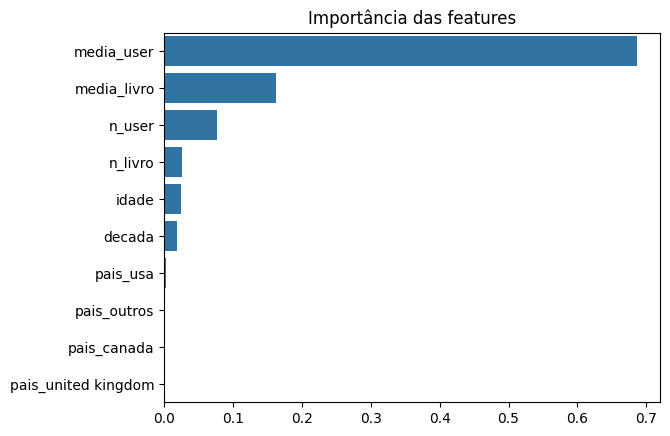

In [52]:
imp = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values(ascending=False).head(10)
sns.barplot(x=imp.values, y=imp.index)
plt.title("Importância das features")
plt.ylabel(None)
plt.show()

O gráfico de importância mostra que o modelo se apoia quase só nas estatísticas de nota: media_user responde por cerca de 69% da importância, media_livro por cerca de 16% e n_user (quantidade de avaliações do usuário) por cerca de 8%. Idade, década de publicação e país têm peso pequeno ou quase nulo. Ou seja, o ganho sobre a média por usuário vem principalmente de combinar o viés do usuário com o do livro, e não dos dados demográficos.

In [51]:
display(pd.DataFrame(resultados).sort_values("RMSE"))

,modelo,RMSE,MAE
6,Random Forest,1.563215,1.198167
5,TruncatedSVD,1.598632,1.234366
2,Média por usuário,1.600658,1.236946
4,KNN com médias,1.619597,1.219844
3,KNN simples,1.634425,1.208850
0,Média global,1.787774,1.425711
1,Média por livro,1.827577,1.436815


## Conclusão

| Modelo | RMSE | MAE |
|---|---|---|
| Random Forest | 1,563 | 1,198 |
| TruncatedSVD | 1,599 | 1,234 |
| Média por usuário | 1,601 | 1,237 |
| KNN com médias | 1,620 | 1,220 |
| KNN simples | 1,634 | 1,209 |
| Média global | 1,788 | 1,426 |
| Média por livro | 1,828 | 1,437 |

O Random Forest teve o melhor desempenho nas duas métricas e foi o único a superar a média por usuário em RMSE e MAE com folga. Ele combina o viés do usuário e o do livro e prevê todo o teste. A média por usuário se mostrou um baseline forte: o gosto de cada usuário explica mais do que qualquer característica do livro. O TruncatedSVD ficou praticamente igual a esse baseline, e os KNN tiveram o menor MAE entre os métodos de vizinhança, mas só atuam nos cerca de 27% dos casos em que encontram vizinhos avaliados pelo usuário. Os demais caem no fallback por causa da esparsidade, que foi a principal limitação do trabalho.

O ganho do Random Forest é moderado e vem quase todo das médias de usuário e de livro. Idade, país e década pouco contribuíram. Como o filtro manteve só usuários com pelo menos 5 avaliações, o resultado vale para usuários mais ativos que o típico.